<a href="https://colab.research.google.com/github/Mitochondrion3000/epic-competiton/blob/main/epic_pipeline_annotated(%D0%BB%D1%83%D1%87%D1%88%D0%B8%D0%B9_%D0%B2%D0%B0%D1%80%D0%B8%D0%B0%D0%BD%D1%82).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EPIC: полный цикл на одном организме, версия с подробными пояснениями

**Идея задачи.** По одной только последовательности ДНК предсказать, в каких позициях генома и на какой цепи начинается транскрипция
(метод csRNA-seq фиксирует 5'-концы РНК, поэтому в данных это «счётчики 5'-концов» в отдельных позициях).

**Поток данных по ячейкам**

```
genome.fa.gz ─────────┐                                   ┌─► обучение (ячейка 14) ─► модель (best.pt)
csRNA-r1/r2-train.bed ┼─► ячейки 7–10: последовательность ─┤
                      │   + метки (где есть 5'-концы)      └─► оценка на val-контигах (ячейка 13)

модель + геном ─► ячейка 15: предсказание по тестовым контигам ─► ячейка 16: сборка по template.test.bed
                                                                 ─► сравнение с ground_truth + маски half1/half2
                                                                 ─► submission.txt.gz
ячейка 17: графики для понимания результата
```

Ячейки с графиками подписаны, как их читать. Все настраиваемые числа собраны в ячейке 6 и описаны там.
Выберите GPU: *Runtime → Change runtime type → T4 GPU*.

## Карта файлов датасета и где они используются

Путь к датасету: `/content/epic/jaNemVect1.1/` (архив `jaNemVect1.1.tgz` распаковывается в ячейке 4).

| Файл | Что это | Где используется |
|---|---|---|
| `genome/genome.fa.gz` | последовательность всех контигов (хромосом) | **ячейка 7**: читается в массивы кодов 0–4 (A,C,G,T,N). Из него берутся входы модели и для train, и для test |
| `for_participants/csRNA-r1-train.bed.gz`, `...-r2-...` | 5'-концы РНК, две реплики, только train-хромосомы. Формат BED6: `chrom, start, end, имя, счёт, цепь` | **ячейка 8**: счёта складываются по двум репликам в массив «сигнал» формы (2 цепи × длина контига). Это и есть метки |
| `for_participants/csRNA-r*-train-unfiltered.bed.gz` | нефильтрованная версия тех же данных | не используется (в правилах не проверял, чем именно отличается фильтрация) |
| `for_participants/rnaseq-*` | обычный RNA-seq (другой тип данных) | не используется. Позже можно попробовать как дополнительный сигнал |
| `for_participants/whitelist.train.bed.gz` | список разрешённых интервалов для train | **ячейка 9**: только диагностика (какая доля положительных позиций попадает в whitelist). В обучении пока не применяется |
| `for_participants/template.test.bed.gz` | **список интервалов для сабмита**: хромосома, начало, конец, цепь | **ячейка 16**: из предсказаний по геному вырезаются эти интервалы |
| `for_participants/template.test.txt.gz` | образец ответа: по числу на каждую позицию интервалов подряд | код не читает; это образец формата для `submission.txt.gz` |
| `for_participants/whitelist.test.bed.gz` | интервалы теста (совпадают с началом `template.test.bed`) | не используется |
| `ground_truth/csRNA-test.txt.gz` | правильные ответы на тесте в порядке `template.test` | **ячейка 16**: офлайн-оценка (AUPRC, Spearman). В настоящем соревновании этого файла у участников нет |
| `scoring/mask1-test.txt.gz`, `mask2-test.txt.gz` | 1/0 для каждой позиции: какие позиции входят в первую и вторую половину оценки | **ячейка 16**: метрики для `half1` и `half2` |
| `scoring/half1-test.bed.gz`, `half2-test.bed.gz` | те же половины в формате интервалов | не используется (маски делают то же самое) |
| `genome/assembly_report.txt`, `genome.fa.fai` | справка о сборке, индекс fasta | не используются |

Файлы `csRNA-train.txt.gz`, `csRNA-r*-train.txt.gz`, `template.train.bed.gz` я не открывал: по названиям это train-аналоги формата «число на позицию интервалов», но для текущего кода они не нужны.

In [1]:
# ЯЧЕЙКА 2. Окружение: библиотеки, GPU, воспроизводимость
import os, re, gzip, json, math, time, random, glob, tarfile, zipfile
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import average_precision_score, precision_recall_curve
from scipy.stats import spearmanr

plt.rcParams["figure.dpi"] = 110
SEED = 0   # фиксируем случайность, чтобы разбиение и батчи повторялись между запусками
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("устройство:", DEVICE, "(на CPU обучение будет очень медленным)")
DATA_DIR = "/content/epic"          # сюда скачиваются и распаковываются файлы
os.makedirs(DATA_DIR, exist_ok=True)

устройство: cuda (на CPU обучение будет очень медленным)


In [2]:
# ЯЧЕЙКА 3. Что лежит в записи Zenodo (doi:10.5281/zenodo.22285753)
import requests
rec = requests.get("https://zenodo.org/api/records/22285753", timeout=60).json()
files = rec.get("files", [])
for f in files:
    print(f"{f['size']/1e6:10.1f} МБ  {f['key']}")

     304.0 МБ  jaNemVect1.1.tgz
       0.0 МБ  genome_metrics.json
    2038.5 МБ  ASM119413v2.tgz
    1328.7 МБ  Ofas_2.0.tgz
     847.2 МБ  cgigas_uk_roslin_v1.tgz
    2428.4 МБ  sSquSuc5.hap2.tgz
     463.2 МБ  ilPloInte3.2.tgz


In [3]:
# ЯЧЕЙКА 4. Скачивание и распаковка нужного архива
# WANT: подстроки имён файлов, которые нужно скачать. Для учебного датасета Nematostella это "jaNemVect1.1".
# Для настоящего вида подставьте часть его имени из списка выше и поменяйте BASE в ячейке 6.
WANT = ["jaNemVect1.1"]

def download(url, dst):
    if os.path.exists(dst): return              # не скачиваем повторно
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(dst, "wb") as fh:
            for chunk in r.iter_content(1 << 20): fh.write(chunk)

for f in files:
    if any(w.lower() in f["key"].lower() for w in WANT):
        dst = os.path.join(DATA_DIR, os.path.basename(f["key"]))
        print("скачиваю", f["key"]); download(f["links"]["self"], dst)
        if dst.endswith(".zip"): zipfile.ZipFile(dst).extractall(DATA_DIR)
        elif dst.endswith((".tar", ".tar.gz", ".tgz")): tarfile.open(dst).extractall(DATA_DIR)

all_files = sorted(p for p in glob.glob(os.path.join(DATA_DIR, "**", "*"), recursive=True) if os.path.isfile(p))
for p in all_files: print(os.path.getsize(p) // 1000, "КБ", p)

скачиваю jaNemVect1.1.tgz


/tmp/ipykernel_1702/2879343791.py:18: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  elif dst.endswith((".tar", ".tar.gz", ".tgz")): tarfile.open(dst).extractall(DATA_DIR)


303967 КБ /content/epic/jaNemVect1.1.tgz
938 КБ /content/epic/jaNemVect1.1/for_participants/csRNA-r1-train-unfiltered.bed.gz
885 КБ /content/epic/jaNemVect1.1/for_participants/csRNA-r1-train.bed.gz
1485 КБ /content/epic/jaNemVect1.1/for_participants/csRNA-r1-train.txt.gz
1750 КБ /content/epic/jaNemVect1.1/for_participants/csRNA-r2-train-unfiltered.bed.gz
1635 КБ /content/epic/jaNemVect1.1/for_participants/csRNA-r2-train.bed.gz
1707 КБ /content/epic/jaNemVect1.1/for_participants/csRNA-r2-train.txt.gz
1321 КБ /content/epic/jaNemVect1.1/for_participants/csRNA-train.txt.gz
857 КБ /content/epic/jaNemVect1.1/for_participants/rnaseq-r1-train-unfiltered.bed.gz
762 КБ /content/epic/jaNemVect1.1/for_participants/rnaseq-r1-train.bed.gz
1453 КБ /content/epic/jaNemVect1.1/for_participants/rnaseq-r1-train.txt.gz
674 КБ /content/epic/jaNemVect1.1/for_participants/rnaseq-r2-train-unfiltered.bed.gz
595 КБ /content/epic/jaNemVect1.1/for_participants/rnaseq-r2-train.bed.gz
1404 КБ /content/epic/jaNemVect

## Форматы данных, с которыми работает код

- **Геном** (`genome.fa.gz`): FASTA, у каждого контига имя вида `NC_064034.1` и последовательность из букв A, C, G, T, N.
  Код переводит букву в число: A=0, C=1, G=2, T=3, N=4 (неизвестная позиция).
- **Метки** (`csRNA-rN-train.bed.gz`): BED6, строка = одна позиция с 5'-концами РНК.
  Пример: `NC_064034.1  51582  51583  имя  44  -` читается как «в позиции 51582 на минус-цепи 44 прочтения».
  Позиций без строки в файле нет, значит там ноль.
- **Сигнал** в коде: для каждого контига массив `signal[контиг]` формы `(2, длина)`; строка 0 = плюс-цепь, строка 1 = минус-цепь,
  значение = сумма счётчиков по двум репликам.
- **Положительная позиция**: сигнал > `PRESENCE_THRESH` (по умолчанию > 0, то есть хотя бы одно прочтение).

In [4]:
# ЯЧЕЙКА 6. Все настраиваемые параметры в одном месте (что меняется — меняйте здесь)
BASE = "/content/epic/jaNemVect1.1"   # папка датасета

# --- данные ---
PRESENCE_THRESH = 0.0   # позиция «положительная», если сумма счётчиков по репликам > этого порога
WIN = 2048              # длина окна ДНК, которое видит модель за раз (в нуклеотидах)
VAL_FRACTION = 0.10     # какую долю длины размеченных контигов отложить для проверки (по контигам, без утечки)

# --- модель ---
CHANNELS = 96                                     # ширина слоёв (число «признаков» на каждую позицию)
DILATIONS = (1, 2, 4, 8, 16, 32, 64, 128, 256)    # шаги расширения свёрток: чем больше, тем дальше модель «видит» вдоль ДНК

# --- обучение ---
STEPS = 6000            # число шагов обучения (одно обновление весов на батч). Для лучшего результата попробуйте 20000–30000
BS = 32                 # окон в батче
LR = 2e-3               # максимальная скорость обучения (меняется по расписанию OneCycle)
POS_FRAC = 0.5          # доля окон в батче, построенных вокруг положительных позиций (иначе почти одни нули)
POS_WEIGHT = 5.0        # во сколько раз ошибка на положительной позиции весит больше, чем на нулевой
EFF_LOSS_WEIGHT = 0.5   # вес регрессионной части (сила инициации) в общей функции потерь
EVAL_EVERY = 1000       # как часто проверять качество на val-контигах

# --- предсказание ---
PAD = 256               # края окна при предсказании отбрасываем: там у модели мало контекста

47 контигов, всего 269.4 Мб
доля неизвестных позиций (N): 0.00013


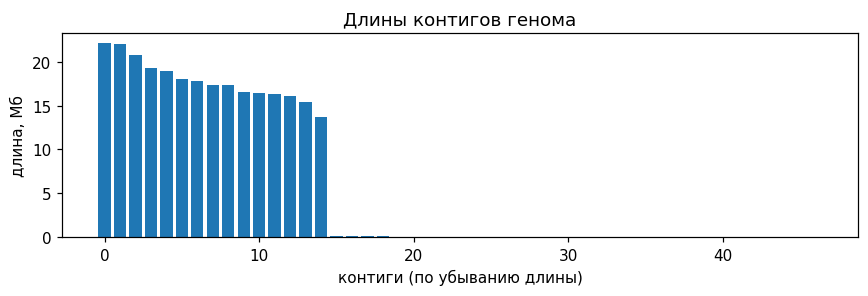

In [5]:
# ЯЧЕЙКА 7. Чтение генома: FASTA -> массивы кодов
# Файл: genome/genome.fa.gz. Для каждого контига получаем numpy-массив длиной L со значениями 0..4.
LUT = np.full(256, 4, np.uint8)               # таблица «код символа -> число», по умолчанию 4 (N)
for i, b in enumerate("ACGT"):
    LUT[ord(b)] = i; LUT[ord(b.lower())] = i  # строчные (мягко маскированные повторы) считаем так же

def read_fasta(path):
    op = gzip.open if path.endswith(".gz") else open
    seqs, name, chunks = {}, None, []
    with op(path, "rt") as fh:
        for line in fh:
            if line.startswith(">"):
                if name is not None: seqs[name] = np.frombuffer("".join(chunks).encode(), np.uint8)
                name = line[1:].split()[0]; chunks = []
            else: chunks.append(line.strip())
    if name is not None: seqs[name] = np.frombuffer("".join(chunks).encode(), np.uint8)
    return {k: LUT[v] for k, v in seqs.items()}

genome = read_fasta(f"{BASE}/genome/genome.fa.gz")
lens_all = {c: len(v) for c, v in genome.items()}
print(len(genome), "контигов, всего", round(sum(lens_all.values()) / 1e6, 1), "Мб")
print("доля неизвестных позиций (N):", round(float(np.mean(np.concatenate([v == 4 for v in genome.values()]))), 5))

# ГРАФИК: длины контигов. Показывает, из каких кусков состоит геном: несколько больших хромосом и/или много мелких.
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.bar(range(len(lens_all)), sorted([v / 1e6 for v in lens_all.values()], reverse=True))
ax.set_xlabel("контиги (по убыванию длины)"); ax.set_ylabel("длина, Мб"); ax.set_title("Длины контигов генома")
plt.tight_layout(); plt.show()

файлы меток: ['csRNA-r1-train.bed.gz', 'csRNA-r2-train.bed.gz']
csRNA-r1-train.bed.gz : строк 94425 , сумма счётчиков 723106
csRNA-r2-train.bed.gz : строк 172973 , сумма счётчиков 2256393
контигов с метками (train): 12 | без меток (test): 35
положительных позиций: 221559 из 433437768 (доля 5.11e-04). Это и есть «случайный» уровень AUPRC.


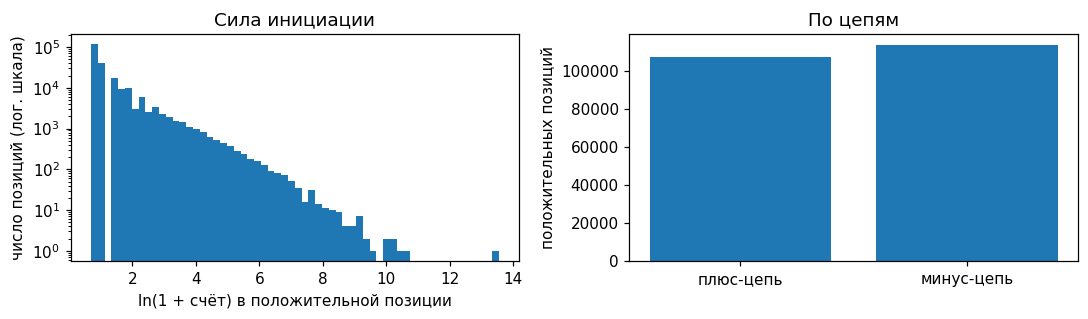

In [6]:
# ЯЧЕЙКА 8. Метки: csRNA-seq 5'-концы -> массив signal[контиг] формы (2 цепи, длина)
# Файлы: for_participants/csRNA-r1-train.bed.gz и csRNA-r2-train.bed.gz (две реплики).
# Столбцы BED6: 0 chrom, 1 start, 2 end, 3 имя, 4 счёт (читаем), 5 цепь (читаем).
TRAIN_TRACKS = sorted(glob.glob(f"{BASE}/for_participants/csRNA-r[0-9]-train.bed.gz"))
print("файлы меток:", [os.path.basename(t) for t in TRAIN_TRACKS])
assert TRAIN_TRACKS, "файлы csRNA-rN-train.bed.gz не найдены, проверьте BASE"

def read_bed6(path):
    return pd.read_csv(path, sep="\t", header=None, usecols=[0, 1, 4, 5],
                       names=["chrom", "start", "val", "strand"], dtype={"chrom": str, "strand": str})

signal = {}   # контиг -> float32 (2, L): строка 0 = плюс-цепь, строка 1 = минус-цепь; сумма по репликам
for t in TRAIN_TRACKS:
    df = read_bed6(t)
    print(os.path.basename(t), ": строк", len(df), ", сумма счётчиков", int(df.val.sum()))
    for (contig, st), d in df.groupby(["chrom", "strand"]):
        if contig not in genome or st not in ("+", "-"): continue
        s = 0 if st == "+" else 1
        if contig not in signal:
            signal[contig] = np.zeros((2, lens_all[contig]), np.float32)
        np.add.at(signal[contig][s], d["start"].values, d["val"].values.astype(np.float32))  # сумма по репликам

assert len(signal) > 0, "ни один трек не загрузился"
test_contigs = [c for c in genome if c not in signal]   # контиги без меток = тестовые
print("контигов с метками (train):", len(signal), "| без меток (test):", len(test_contigs))

tot = sum(s.shape[1] for s in signal.values()) * 2
pos = sum(int((s > PRESENCE_THRESH).sum()) for s in signal.values())
print(f"положительных позиций: {pos} из {tot} (доля {pos/tot:.2e}). Это и есть «случайный» уровень AUPRC.")

# ГРАФИК: распределение силы инициации в положительных позициях. Читать так: по оси X лог-сила (ln(1+счёт)),
# по оси Y число позиций. Резкий спад вправо означает, что большинство позиций слабые (1–3 прочтения), сильных мало.
vals = np.concatenate([s[s > PRESENCE_THRESH] for s in signal.values()])
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(np.log1p(vals), bins=60); ax[0].set_yscale("log")
ax[0].set_xlabel("ln(1 + счёт) в положительной позиции"); ax[0].set_ylabel("число позиций (лог. шкала)"); ax[0].set_title("Сила инициации")
ax[1].bar(["плюс-цепь", "минус-цепь"], [sum(int((s[i] > PRESENCE_THRESH).sum()) for s in signal.values()) for i in (0, 1)])
ax[1].set_ylabel("положительных позиций"); ax[1].set_title("По цепям")
plt.tight_layout(); plt.show()

In [7]:
# ЯЧЕЙКА 9. Диагностика: файл whitelist.train.bed.gz
# Только смотрим, какая доля генома и положительных позиций лежит внутри whitelist. В обучении whitelist пока НЕ используется.
wl = pd.read_csv(f"{BASE}/for_participants/whitelist.train.bed.gz", sep="\t", header=None,
                 usecols=[0, 1, 2], names=["chrom", "start", "end"], dtype={"chrom": str})
inwl = {c: np.zeros(lens_all[c], bool) for c in signal}
for c, s, e in zip(wl.chrom, wl.start, wl.end):
    if c in inwl: inwl[c][s:e] = True
pos_any = {c: (signal[c] > PRESENCE_THRESH).any(0) for c in signal}
cover = sum(int(m.sum()) for m in inwl.values()) / sum(lens_all[c] for c in signal)
inside = sum(int((pos_any[c] & inwl[c]).sum()) for c in signal) / max(1, sum(int(p.sum()) for p in pos_any.values()))
print(f"whitelist покрывает {cover:.1%} длины train-контигов и содержит {inside:.1%} положительных позиций")
print("Если вторая доля сильно выше первой, whitelist отбирает «осмысленные» участки; "
      "тогда есть смысл учить и оценивать модель в основном внутри него.")

whitelist покрывает 72.0% длины train-контигов и содержит 100.0% положительных позиций
Если вторая доля сильно выше первой, whitelist отбирает «осмысленные» участки; тогда есть смысл учить и оценивать модель в основном внутри него.


train-контигов: 10 | val-контигов: 2 (31.1 Мб)
положительных позиций для выборки окон: 197229


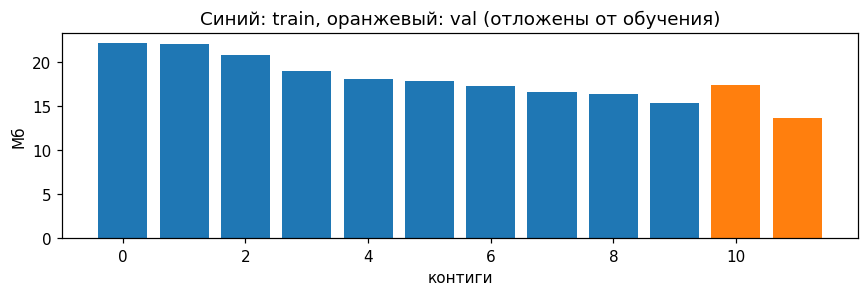

In [8]:
# ЯЧЕЙКА 10. Разбиение на train и val (по контигам) и индекс положительных позиций
# Почему по контигам: соседние окна одной хромосомы почти одинаковы, и при случайном разбиении val-метрика была бы завышена.
labeled = [c for c in signal if lens_all[c] >= WIN]
rng = np.random.RandomState(SEED)
order = list(rng.permutation(labeled))
total_len = sum(lens_all[c] for c in labeled)
val_contigs, acc = [], 0
for c in order:
    if acc >= VAL_FRACTION * total_len: break
    val_contigs.append(c); acc += lens_all[c]
vset = set(val_contigs)
train_contigs = [c for c in labeled if c not in vset]
print("train-контигов:", len(train_contigs), "| val-контигов:", len(val_contigs), f"({acc/1e6:.1f} Мб)")

# индекс всех положительных позиций (по любой из цепей) в train-контигах: из него строятся окна «вокруг положительных»
pos_c, pos_i = [], []
for ci, c in enumerate(train_contigs):
    p = np.flatnonzero((signal[c] > PRESENCE_THRESH).any(0))
    pos_c.append(np.full(len(p), ci)); pos_i.append(p)
pos_c = np.concatenate(pos_c); pos_i = np.concatenate(pos_i)
print("положительных позиций для выборки окон:", len(pos_i))

# ГРАФИК: какие контиги пошли в обучение, а какие на проверку. Тестовые контиги (без меток) здесь не показаны.
fig, ax = plt.subplots(figsize=(8, 2.8))
names = train_contigs + val_contigs
ax.bar(range(len(names)), [lens_all[c] / 1e6 for c in names], color=["tab:blue"] * len(train_contigs) + ["tab:orange"] * len(val_contigs))
ax.set_xlabel("контиги"); ax.set_ylabel("Мб"); ax.set_title("Синий: train, оранжевый: val (отложены от обучения)")
plt.tight_layout(); plt.show()

## Как устроена модель

**Вход**: окно ДНК длиной `WIN` = 2048 нуклеотидов, каждая позиция кодируется one-hot (A, C, G, T → четыре числа 0/1; N → четыре нуля).

**Тело сети** (dilated CNN, это свёрточная сеть, которая «растягивает» шаги свёртки, чтобы смотреть далеко вдоль последовательности):
1. *stem*: одна свёртка с окном 15 нуклеотидов, из 4 каналов в `CHANNELS` = 96. Ищет короткие мотивы.
2. 9 *блоков* (по числу `DILATIONS`). Каждый блок: нормализация, активация GELU, свёртка с окном 3 и шагом расширения `d`, ещё одна нормализация, GELU и свёртка 1×1. Результат прибавляется ко входу блока (остаточная связь, она помогает глубоким сетям обучаться).
3. *head*: свёртка 1×1 в 4 выходных канала.

**Выход** для каждой из `WIN` позиций: 4 числа.
- каналы 0 и 1: логит «здесь есть инициация» для плюс и минус цепи (через сигмоиду превращается в вероятность `p`);
- каналы 2 и 3: предсказанная лог-сила инициации `eff` = ln(1 + счёт) для плюс и минус цепи.

**Рецептивное поле**: сколько нуклеотидов вокруг позиции влияют на предсказание; для этой сети его считает ячейка 12.

**Функция потерь** (ячейка 14): BCE (двоичная кросс-энтропия) по наличию с повышенным весом положительных (`POS_WEIGHT`) + Huber-loss по силе только в положительных позициях, умноженный на `EFF_LOSS_WEIGHT`.

**Аугментация**: с вероятностью 1/2 окно заменяется на обратно-комплементарное (читаем ДНК с другой цепи): последовательность разворачивается и дополняется, а цепи в метках меняются местами.

параметров всего: 343,204
  stem (свёртка 15)        5,856
  9 блоков               336,960
  head (4 выхода)            388
рецептивное поле: 1037 нуклеотидов (модель использует контекст примерно ±518 вокруг позиции)
размер окна WIN = 2048, значит у позиций ближе чем 518 к краю окна контекста меньше (потому в предсказании есть PAD = 256)


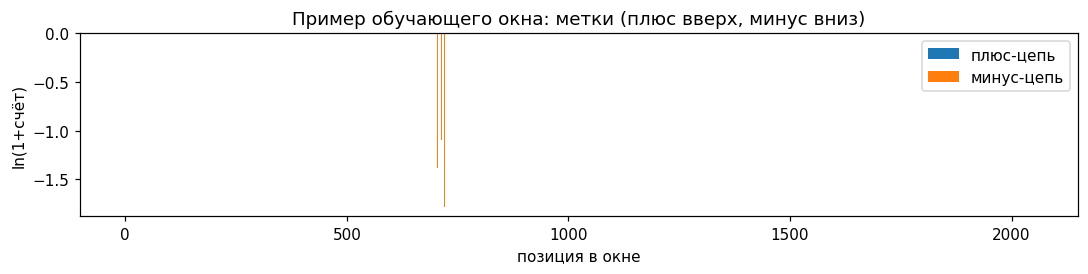

In [9]:
# ЯЧЕЙКА 12. Батчи, модель, сводка по модели
COMP = np.array([3, 2, 1, 0, 4], np.uint8)   # дополнение: A<->T (0<->3), C<->G (1<->2), N остаётся N
lens = np.array([lens_all[c] for c in train_contigs], dtype=np.float64)

def make_batch(bs=32, pos_frac=0.5):
    # Возвращает X (bs, WIN) коды нуклеотидов и Y (bs, 2, WIN) счётчики [плюс, минус] для тех же позиций
    X = np.empty((bs, WIN), np.int64); Y = np.empty((bs, 2, WIN), np.float32)
    for k in range(bs):
        if rng.rand() < pos_frac:
            # окно вокруг случайной положительной позиции (она попадает в случайное место окна)
            j = rng.randint(len(pos_i)); c = train_contigs[pos_c[j]]
            start = int(np.clip(pos_i[j] - rng.randint(WIN), 0, lens_all[c] - WIN))
        else:
            # равномерно случайное окно по train-контигам (вероятность пропорциональна длине контига)
            c = train_contigs[rng.choice(len(train_contigs), p=lens / lens.sum())]
            start = rng.randint(0, lens_all[c] - WIN + 1)
        x, y = genome[c][start:start + WIN], signal[c][:, start:start + WIN]
        if rng.rand() < 0.5:                       # reverse-complement: развернуть ДНК, поменять цепи местами
            x = COMP[x][::-1]; y = y[::-1, ::-1]
        X[k] = x; Y[k] = y
    return torch.from_numpy(X), torch.from_numpy(np.ascontiguousarray(Y))

def onehot(x):   # (B, L) целые коды -> (B, 4, L) из нулей и единиц; N (код 4) -> четыре нуля
    return F.one_hot(x.long(), 5)[..., :4].permute(0, 2, 1).float()

class Block(nn.Module):
    # остаточный блок: нормализация -> GELU -> свёртка (шаг d) -> нормализация -> GELU -> свёртка 1x1, и результат прибавляется ко входу
    def __init__(self, ch, d):
        super().__init__()
        self.c1 = nn.Conv1d(ch, ch, 3, padding=d, dilation=d); self.b1 = nn.BatchNorm1d(ch)
        self.c2 = nn.Conv1d(ch, ch, 1); self.b2 = nn.BatchNorm1d(ch)
    def forward(self, x):
        h = self.c1(F.gelu(self.b1(x)))
        h = self.c2(F.gelu(self.b2(h)))
        return x + h

class Net(nn.Module):
    # выходы по позиции: [0:2] логит наличия (+,-), [2:4] лог-сила инициации (+,-)
    def __init__(self, ch=CHANNELS, dil=DILATIONS):
        super().__init__()
        self.stem = nn.Conv1d(4, ch, 15, padding=7)
        self.blocks = nn.Sequential(*[Block(ch, d) for d in dil])
        self.head = nn.Conv1d(ch, 4, 1)
    def forward(self, x):
        return self.head(F.gelu(self.blocks(self.stem(onehot(x)))))

model = Net().to(DEVICE)

# --- сводка по модели ---
n = lambda m: sum(p.numel() for p in m.parameters())
rf = 1 + (15 - 1) + sum(2 * d for d in DILATIONS)   # размер рецептивного поля в нуклеотидах
print(f"параметров всего: {n(model):,}")
for name, m in [("stem (свёртка 15)", model.stem), (f"{len(DILATIONS)} блоков", model.blocks), ("head (4 выхода)", model.head)]:
    print(f"  {name:20s} {n(m):>9,}")
print(f"рецептивное поле: {rf} нуклеотидов (модель использует контекст примерно ±{rf//2} вокруг позиции)")
print(f"размер окна WIN = {WIN}, значит у позиций ближе чем {rf//2} к краю окна контекста меньше (потому в предсказании есть PAD = {PAD})")

# ГРАФИК: что видит модель в обучающем окне. Сверху: сигнал на плюс-цепи (вверх) и минус-цепи (вниз) в виде ln(1+счёт);
# столбики — это «правильный ответ», который модель должна предсказать по одной только последовательности ДНК.
Xb, Yb = make_batch(1, pos_frac=1.0)
y = np.log1p(Yb[0].numpy())
fig, ax = plt.subplots(figsize=(10, 2.6))
ax.bar(np.arange(WIN), y[0], width=1.0, label="плюс-цепь"); ax.bar(np.arange(WIN), -y[1], width=1.0, label="минус-цепь")
ax.axhline(0, color="k", lw=0.5); ax.set_xlabel("позиция в окне"); ax.set_ylabel("ln(1+счёт)")
ax.set_title("Пример обучающего окна: метки (плюс вверх, минус вниз)"); ax.legend()
plt.tight_layout(); plt.show()

In [10]:
# ЯЧЕЙКА 13. Оценка качества
# Используются две метрики (в моей реализации; официальный скорер может отличаться в деталях):
#  - AUPRC: насколько хорошо скор отделяет положительные позиции от нулевых. Случайный уровень равен доле положительных (pos_rate).
#  - Spearman: ранговая корреляция скора с настоящей силой, считается только в истинных положительных позициях.
# Для разных вариантов итогового скора: presence = только p; combined = p * expm1(eff).
def predict_windows(model, X, bs=64):
    model.eval(); out = []
    with torch.no_grad(), torch.autocast(DEVICE, enabled=(DEVICE == "cuda")):
        for i in range(0, len(X), bs):
            out.append(model(X[i:i + bs].to(DEVICE)).float().cpu())
    return torch.cat(out)

def score_from_out(o):
    p = torch.sigmoid(o[:, :2])                 # вероятность инициации
    eff = o[:, 2:]                              # предсказанная лог-сила
    return p, eff, p * torch.expm1(eff.clamp(min=0))   # третье: «ожидаемая сила» = вероятность * сила

def evaluate(model, contigs, max_bases=20_000_000):
    Xs, Ys = [], []
    for c in contigs:                           # нарезаем val-контиги на непересекающиеся окна
        for k in range(lens_all[c] // WIN):
            Xs.append(genome[c][k * WIN:(k + 1) * WIN]); Ys.append(signal[c][:, k * WIN:(k + 1) * WIN])
    idx = np.random.RandomState(1).permutation(len(Xs))[: max(1, max_bases // (2 * WIN))]   # подвыборка для скорости
    X = torch.from_numpy(np.stack([Xs[i] for i in idx]).astype(np.int64)); Y = np.stack([Ys[i] for i in idx])
    p, eff, sc = score_from_out(predict_windows(model, X))
    mask = (X != 4).unsqueeze(1).expand(-1, 2, -1).numpy().ravel()    # позиции с N не оцениваем
    y = (Y > PRESENCE_THRESH).ravel()[mask]
    res = {"AUPRC_presence": average_precision_score(y, p.numpy().ravel()[mask]),
           "AUPRC_combined": average_precision_score(y, sc.numpy().ravel()[mask])}
    ypos = np.log1p(Y.ravel()[mask][y])
    res["Spearman_eff"] = spearmanr(eff.numpy().ravel()[mask][y], ypos).correlation
    res["Spearman_combined"] = spearmanr(sc.numpy().ravel()[mask][y], ypos).correlation
    res["pos_rate"] = float(y.mean())
    return res

обучение:   0%|          | 0/6000 [00:00<?, ?шаг/s]

шаг 1000: {'AUPRC_presence': 0.0089, 'AUPRC_combined': 0.0092, 'Spearman_eff': 0.3325, 'Spearman_combined': 0.3282, 'pos_rate': 0.0004, 'step': 1000.0}
  новый лучший AUPRC_combined: 0.0092, модель сохранена в /content/best.pt
шаг 2000: {'AUPRC_presence': 0.0172, 'AUPRC_combined': 0.0132, 'Spearman_eff': 0.3356, 'Spearman_combined': 0.33, 'pos_rate': 0.0004, 'step': 2000.0}
  новый лучший AUPRC_combined: 0.0132, модель сохранена в /content/best.pt
шаг 3000: {'AUPRC_presence': 0.0233, 'AUPRC_combined': 0.0185, 'Spearman_eff': 0.3849, 'Spearman_combined': 0.3756, 'pos_rate': 0.0004, 'step': 3000.0}
  новый лучший AUPRC_combined: 0.0185, модель сохранена в /content/best.pt
шаг 4000: {'AUPRC_presence': 0.03, 'AUPRC_combined': 0.0228, 'Spearman_eff': 0.383, 'Spearman_combined': 0.373, 'pos_rate': 0.0004, 'step': 4000.0}
  новый лучший AUPRC_combined: 0.0228, модель сохранена в /content/best.pt
шаг 5000: {'AUPRC_presence': 0.0381, 'AUPRC_combined': 0.0261, 'Spearman_eff': 0.3799, 'Spearman_c

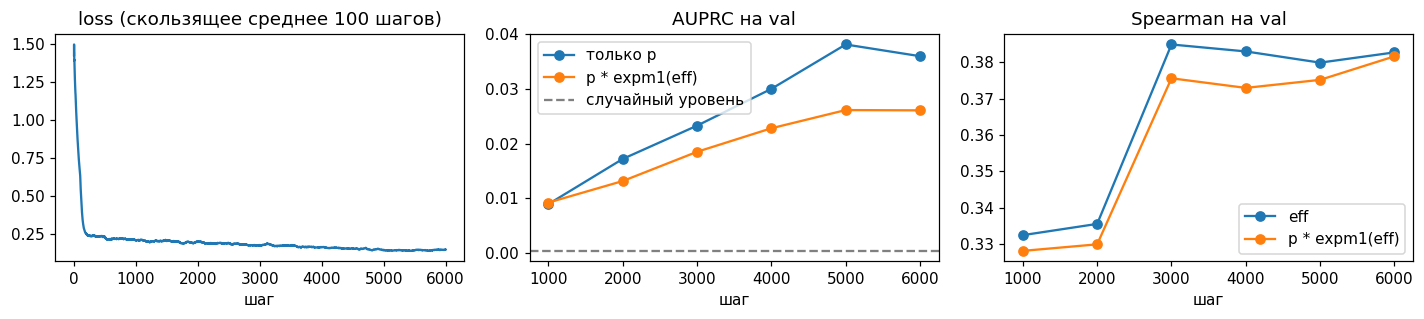

In [11]:
# ЯЧЕЙКА 14. Обучение с прогресс-баром и записью истории
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-2)             # оптимизатор
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=STEPS, pct_start=0.1)  # разогрев 10% шагов, затем спад
scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda"))                  # смешанная точность на GPU
best, ema_loss = -1, None
loss_hist, val_hist = [], []

pbar = tqdm(range(1, STEPS + 1), desc="обучение", unit="шаг")
for step in pbar:
    model.train()
    X, Y = make_batch(BS, POS_FRAC)
    X, Y = X.to(DEVICE), Y.to(DEVICE)
    with torch.autocast(DEVICE, enabled=(DEVICE == "cuda")):
        o = model(X)
    o = o.float()                                           # (BS, 4, WIN)
    tgt = (Y > PRESENCE_THRESH).float()                     # 1, где есть инициация
    l_pres = F.binary_cross_entropy_with_logits(o[:, :2], tgt, pos_weight=torch.tensor(POS_WEIGHT, device=DEVICE))
    m = tgt.bool()
    l_eff = F.smooth_l1_loss(o[:, 2:][m], torch.log1p(Y)[m]) if m.any() else o.sum() * 0   # сила: только там, где инициация есть
    loss = l_pres + EFF_LOSS_WEIGHT * l_eff
    opt.zero_grad(set_to_none=True)
    scaler.scale(loss).backward(); scaler.unscale_(opt)
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)       # обрезаем слишком большие градиенты
    scaler.step(opt); scaler.update(); sched.step()

    li = loss.item(); loss_hist.append(li)
    ema_loss = li if ema_loss is None else 0.98 * ema_loss + 0.02 * li
    pbar.set_postfix(loss=f"{ema_loss:.4f}", best_auprc=f"{best:.4f}" if best >= 0 else "-")

    if step % EVAL_EVERY == 0:
        r = evaluate(model, val_contigs); r["step"] = step; val_hist.append(r)
        tqdm.write(f"шаг {step}: " + str({k: round(float(v), 4) for k, v in r.items()}))
        if r["AUPRC_combined"] > best:
            best = r["AUPRC_combined"]; torch.save(model.state_dict(), "/content/best.pt")
            tqdm.write(f"  новый лучший AUPRC_combined: {best:.4f}, модель сохранена в /content/best.pt")

model.load_state_dict(torch.load("/content/best.pt"))   # возвращаем лучшую по val версию
print("лучший AUPRC_combined на val:", best)

# ГРАФИКИ обучения. Слева: loss (сглажен). Он должен падать и выходить на плато.
# В центре: AUPRC на val; пунктир — случайный уровень (доля положительных). Чем выше над пунктиром, тем лучше.
# Справа: Spearman в положительных позициях. Если val-метрики перестали расти, а loss падает, начинается переобучение.
sm = pd.Series(loss_hist).rolling(100, min_periods=1).mean()
st = [r["step"] for r in val_hist]
fig, ax = plt.subplots(1, 3, figsize=(13, 3))
ax[0].plot(sm); ax[0].set_xlabel("шаг"); ax[0].set_title("loss (скользящее среднее 100 шагов)")
ax[1].plot(st, [r["AUPRC_presence"] for r in val_hist], "o-", label="только p")
ax[1].plot(st, [r["AUPRC_combined"] for r in val_hist], "o-", label="p * expm1(eff)")
ax[1].axhline(val_hist[0]["pos_rate"], ls="--", color="gray", label="случайный уровень"); ax[1].set_title("AUPRC на val"); ax[1].set_xlabel("шаг"); ax[1].legend()
ax[2].plot(st, [r["Spearman_eff"] for r in val_hist], "o-", label="eff"); ax[2].plot(st, [r["Spearman_combined"] for r in val_hist], "o-", label="p * expm1(eff)")
ax[2].set_title("Spearman на val"); ax[2].set_xlabel("шаг"); ax[2].legend()
plt.tight_layout(); plt.show()

In [12]:
# ЯЧЕЙКА 15. Предсказание по контигу (скользящее окно)
# Контиги длиннее WIN режем на окна с перекрытием; из каждого окна берём центр (без PAD по краям), края склеиваем.
# Каждое окно считаем дважды: на прямой цепи и на обратно-комплементарной, результаты усредняем (улучшает стабильность).
# Результат: словарь из массивов (2, L) [плюс, минус]: p, eff, score = p*expm1(eff), p*eff.
def predict_contig(c, desc=None):
    x = genome[c].astype(np.int64); L = len(x); S = WIN - 2 * PAD
    out = {k: np.zeros((2, L), np.float32) for k in ("p", "eff", "score", "p*eff")}
    starts = list(range(0, max(L - WIN, 0) + 1, S))
    if starts[-1] + WIN < L: starts.append(L - WIN)
    for st in tqdm(starts, desc=desc or c, unit="окно", leave=False):
        w = x[st:st + WIN]
        if len(w) < WIN: w = np.pad(w, (0, WIN - len(w)), constant_values=4)
        wr = COMP[w][::-1].astype(np.int64)                   # обратно-комплементарное окно
        o2 = predict_windows(model, torch.from_numpy(np.stack([w, wr]).copy()))
        orc = o2[1][[1, 0, 3, 2]].flip(-1)                    # вернуть RC-ответ в исходную систему: поменять цепи, развернуть ось
        o = 0.5 * (o2[0] + orc)
        p, eff, sc = [t[0].numpy() for t in score_from_out(o[None])]
        a, b = (0 if st == 0 else PAD), WIN - (PAD if st + WIN < L else 0)
        k = min(b, L - st) - a
        for name, arr in (("p", p), ("eff", eff), ("score", sc), ("p*eff", p * np.maximum(eff, 0))):
            out[name][:, st + a: st + a + k] = arr[:, a:a + k]
    return out

# какие контиги нужны для сабмита: те, что перечислены в template.test.bed
tb = pd.read_csv(f"{BASE}/for_participants/template.test.bed.gz", sep="\t", header=None,
                 names=["chrom", "start", "end", "name", "score", "strand"], dtype={"chrom": str, "strand": str})
need = sorted(set(tb.chrom))
print("контиги в template.test.bed:", need)
preds = {c: predict_contig(c) for c in tqdm(need, desc="контиги", unit="контиг")}

контиги в template.test.bed: ['NC_064037.1', 'NC_064044.1', 'NC_064046.1']


контиги:   0%|          | 0/3 [00:00<?, ?контиг/s]

NC_064037.1:   0%|          | 0/12578 [00:00<?, ?окно/s]

NC_064044.1:   0%|          | 0/10684 [00:00<?, ?окно/s]

NC_064046.1:   0%|          | 0/10508 [00:00<?, ?окно/s]

In [13]:
# ЯЧЕЙКА 16. Сборка сабмита по template.test.bed, офлайн-оценка и запись файла
# template.test.bed.gz: список интервалов (хромосома, начало, конец, цепь).
# Сабмит = столбик чисел: сначала все позиции первого интервала по порядку, затем второго и так далее (как в template.test.txt.gz).
tb["len"] = tb.end - tb.start
n_total = int(tb.len.sum()); print("позиций в шаблоне:", n_total)
def read_col(path, dtype=np.float32): return pd.read_csv(path, header=None, dtype=dtype)[0].values
gt = read_col(f"{BASE}/ground_truth/csRNA-test.txt.gz")                  # правильные ответы в том же порядке
m1 = read_col(f"{BASE}/scoring/mask1-test.txt.gz", np.int8).astype(bool)  # позиции первой половины оценки
m2 = read_col(f"{BASE}/scoring/mask2-test.txt.gz", np.int8).astype(bool)  # позиции второй половины
assert len(gt) == len(m1) == len(m2) == n_total, "длины файлов не совпали"

def assemble(key, rev_minus=False):
    parts = []
    for c, s, e, st in zip(tb.chrom, tb.start, tb.end, tb.strand):
        v = preds[c][key][0 if st == "+" else 1, s:e]
        parts.append(v[::-1] if (rev_minus and st == "-") else v)
    return np.concatenate(parts)

def score(pred, mask):
    y = gt[mask] > 0
    return {"AUPRC": float(average_precision_score(y, pred[mask])),
            "Spearman": float(spearmanr(pred[mask][y], gt[mask][y]).correlation)}

full = np.ones(n_total, bool)
# проверка порядка позиций на минус-цепи (слева направо или справа налево); у вас по возрастанию дал заметно лучший результат
r_asc, r_rev = score(assemble("score", False), full), score(assemble("score", True), full)
REV_MINUS = r_rev["AUPRC"] > r_asc["AUPRC"]
print("минус-цепь по возрастанию:", {k: round(v, 4) for k, v in r_asc.items()}, "| развёрнута:", {k: round(v, 4) for k, v in r_rev.items()}, "-> REV_MINUS =", REV_MINUS)

# Сравнение вариантов итогового скора на всём тесте и на двух половинах оценки
VARIANTS = ["p", "eff", "score", "p*eff"]
cands = {k: assemble(k, REV_MINUS) for k in VARIANTS}
rows = []
for k in VARIANTS:
    for nm, mk in (("всё", full), ("half1", m1), ("half2", m2)):
        rows.append({"скор": k, "часть": nm, **{a: round(b, 4) for a, b in score(cands[k], mk).items()}})
table = pd.DataFrame(rows).pivot(index="скор", columns="часть", values=["AUPRC", "Spearman"])
print(table)
print("pos_rate на всём тесте:", round(float((gt > 0).mean()), 6), "(случайный уровень AUPRC)")

# какой вариант записать в сабмит (проверьте таблицу выше)
FINAL_VARIANT = "score"
final = cands[FINAL_VARIANT]
os.makedirs("/content/submission", exist_ok=True)
pd.Series(final).to_csv("/content/submission/submission.txt.gz", header=False, index=False, float_format="%.6g", compression="gzip")
print("записано строк:", len(final), "-> /content/submission/submission.txt.gz (вариант:", FINAL_VARIANT + ")")

позиций в шаблоне: 72613390
минус-цепь по возрастанию: {'AUPRC': 0.0434, 'Spearman': 0.379} | развёрнута: {'AUPRC': 0.0137, 'Spearman': 0.1315} -> REV_MINUS = False
        AUPRC                 Spearman                
часть   half1   half2     всё    half1   half2     всё
скор                                                  
eff    0.0308  0.0199  0.0233   0.3927  0.3941  0.3933
p      0.0718  0.0458  0.0561   0.3694  0.3565  0.3634
p*eff  0.0636  0.0395  0.0483   0.3797  0.3680  0.3743
score  0.0566  0.0358  0.0434   0.3841  0.3732  0.3790
pos_rate на всём тесте: 0.000741 (случайный уровень AUPRC)
записано строк: 72613390 -> /content/submission/submission.txt.gz (вариант: score)


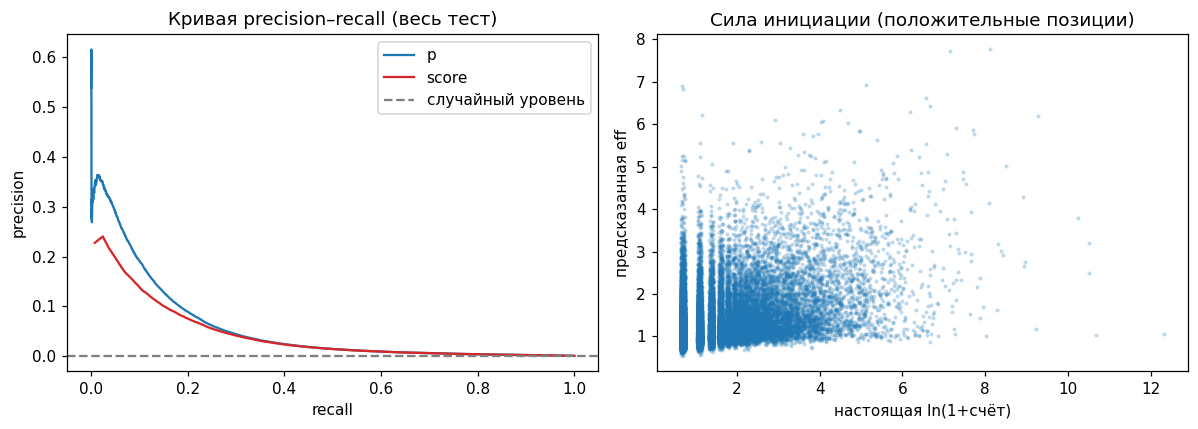

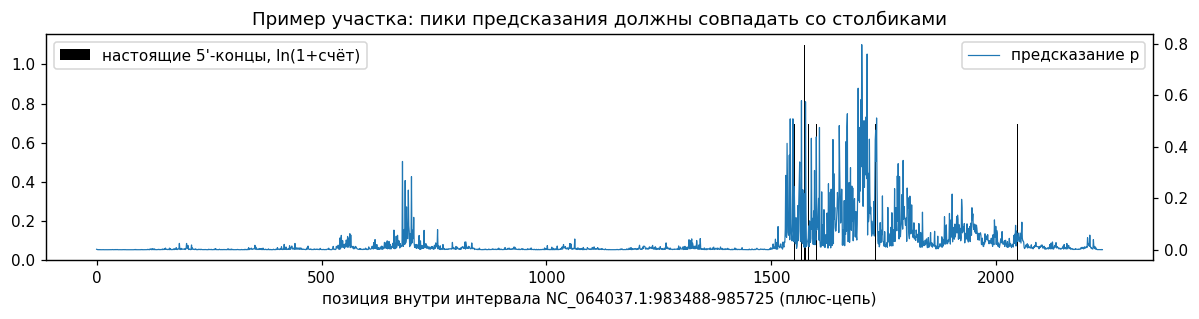

In [14]:
# ЯЧЕЙКА 17. Графики для понимания результата на тесте
# 1) Кривая precision–recall: по оси X доля найденных настоящих позиций, по оси Y точность среди выбранных.
#    Чем выше и правее кривая, тем лучше; серая пунктирная линия — случайный уровень (доля положительных).
# 2) Предсказанная и настоящая сила в положительных позициях: облако вдоль диагонали означает хорошее ранжирование по силе.
# 3) Участок генома: настоящие 5'-концы (столбики) и предсказания модели (линии) вдоль одной позиции.
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k, col in (("p", "tab:blue"), ("score", "tab:red")):
    pr, rc, _ = precision_recall_curve(gt > 0, cands[k])
    step = max(1, len(pr) // 3000)
    ax[0].plot(rc[::step], pr[::step], color=col, label=k)
ax[0].axhline(float((gt > 0).mean()), ls="--", color="gray", label="случайный уровень")
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_title("Кривая precision–recall (весь тест)"); ax[0].legend()
posm = gt > 0
ax[1].scatter(np.log1p(gt[posm]) + np.random.uniform(-0.05, 0.05, posm.sum()), cands["eff"][posm], s=3, alpha=0.2)
ax[1].set_xlabel("настоящая ln(1+счёт)"); ax[1].set_ylabel("предсказанная eff"); ax[1].set_title("Сила инициации (положительные позиции)")
plt.tight_layout(); plt.show()

# участок: берём первый плюс-интервал короче 4000 позиций, где есть минимум 3 положительные позиции
off = np.cumsum(tb.len.values) - tb.len.values
pick = None
for i, (ln, st) in enumerate(zip(tb.len.values, tb.strand.values)):
    if st == "+" and ln <= 4000 and (gt[off[i]:off[i] + ln] > 0).sum() >= 3: pick = i; break
if pick is not None:
    a, b = off[pick], off[pick] + tb.len.values[pick]
    fig, ax = plt.subplots(figsize=(11, 3))
    ax.bar(np.arange(b - a), np.log1p(gt[a:b]), width=1.5, color="k", label="настоящие 5'-концы, ln(1+счёт)")
    ax2 = ax.twinx(); ax2.plot(cands["p"][a:b], color="tab:blue", lw=0.8, label="предсказание p")
    ax.set_xlabel(f"позиция внутри интервала {tb.chrom[pick]}:{tb.start[pick]}-{tb.end[pick]} (плюс-цепь)")
    ax.set_title("Пример участка: пики предсказания должны совпадать со столбиками"); ax.legend(loc="upper left"); ax2.legend(loc="upper right")
    plt.tight_layout(); plt.show()

## Что менять дальше

1. Сравните варианты скора в таблице ячейки 16 (`p`, `eff`, `score`, `p*eff`) и выберите `FINAL_VARIANT` по тому, какая метрика важнее в правилах: AUPRC или Spearman.
2. Увеличьте `STEPS` до 20000–30000: кривая val-метрик в конце обучения обычно ещё растёт.
3. Меняйте по одному параметру за раз (ячейка 6: `WIN`, `CHANNELS`, `DILATIONS`, `POS_WEIGHT`) и сравнивайте таблицу ячейки 16.
4. Проверьте идею с whitelist (ячейка 9): если почти все положительные позиции лежат внутри него, учите и оценивайте модель только там.
5. Для настоящего вида: поменяйте `WANT` в ячейке 4 и `BASE` в ячейке 6. У настоящих видов не будет `ground_truth` и масок, поэтому ячейка 16 там дойдёт только до записи файла (оценка закомментируется или будет пропускаться).